In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)
X_fake = np.random.randn(800, 4) * 5 + 10  # dimenzije
y_fake = np.random.randint(0, 10, 800)

In [7]:

X_train, X_test, y_train, y_test = train_test_split(X_fake, y_fake, test_size=0.1, random_state=42)

In [8]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [9]:
X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.LongTensor(y_train)
X_test_t = torch.FloatTensor(X_test)
y_test_t = torch.LongTensor(y_test)

In [10]:
X_train_t


tensor([[-2.2500,  0.7893, -0.5879, -0.1387],
        [ 0.4073, -0.6761,  0.0453, -0.2036],
        [ 0.3131, -0.6950, -0.2548, -0.5397],
        ...,
        [-0.3446, -0.4189, -0.3703,  2.0211],
        [-0.0895, -0.2367,  0.0284,  1.1094],
        [ 0.1452,  0.4531,  0.6816, -1.1692]])

In [11]:
class ArchaeologicalClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, 32)
        self.relu = nn.ReLU()
        self.layer2 = nn.Linear(32, num_classes)
        
    def forward(self, x):
        x = self.layer1(x)
        x = self.relu(x)
        x = self.layer2(x) # Izlaz su takozvani 'logits' za svaku klasu
        return x

In [12]:
model = ArchaeologicalClassifier(input_dim=4, num_classes=10)


# --- KORAK 3: Trening petlja ---
criterion = nn.CrossEntropyLoss() # Standardno za klasifikaciju
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [16]:
epochs = 2000
loss_history = []
for epoch in range(epochs):
    model.train()
    
    # Forward pass
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    
    loss_history.append(loss.item())
    
    # Backward pass i optimizacija
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')

Epoch [10/2000], Loss: 1.7459
Epoch [20/2000], Loss: 1.7456
Epoch [30/2000], Loss: 1.7457
Epoch [40/2000], Loss: 1.7457
Epoch [50/2000], Loss: 1.7450
Epoch [60/2000], Loss: 1.7447
Epoch [70/2000], Loss: 1.7445
Epoch [80/2000], Loss: 1.7446
Epoch [90/2000], Loss: 1.7442
Epoch [100/2000], Loss: 1.7440
Epoch [110/2000], Loss: 1.7438
Epoch [120/2000], Loss: 1.7433
Epoch [130/2000], Loss: 1.7430
Epoch [140/2000], Loss: 1.7427
Epoch [150/2000], Loss: 1.7432
Epoch [160/2000], Loss: 1.7424
Epoch [170/2000], Loss: 1.7423
Epoch [180/2000], Loss: 1.7423
Epoch [190/2000], Loss: 1.7422
Epoch [200/2000], Loss: 1.7423
Epoch [210/2000], Loss: 1.7423
Epoch [220/2000], Loss: 1.7421
Epoch [230/2000], Loss: 1.7421
Epoch [240/2000], Loss: 1.7420
Epoch [250/2000], Loss: 1.7420
Epoch [260/2000], Loss: 1.7422
Epoch [270/2000], Loss: 1.7419
Epoch [280/2000], Loss: 1.7418
Epoch [290/2000], Loss: 1.7421
Epoch [300/2000], Loss: 1.7421
Epoch [310/2000], Loss: 1.7418
Epoch [320/2000], Loss: 1.7418
Epoch [330/2000],

In [18]:
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test_t).sum().item() / len(y_test_t)
    print(f'\nTačnost na test skupu: {accuracy * 100:.2f}%')


Tačnost na test skupu: 15.00%


C:\Users\Nikola\AppData\Local\Temp\ipykernel_16948\2334899465.py:4: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


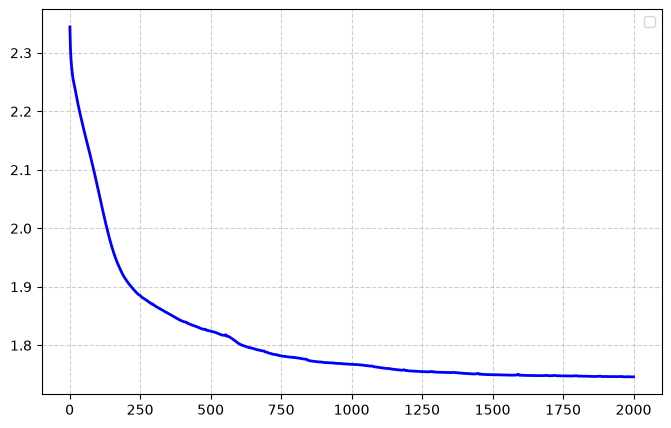

In [15]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history, color='b', linewidth=2)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()